# 1. Making zoom initial conditions (with MUSIC-2)

Before we can run a zoom simulation, we need initial conditions to run... this normally entails choosing a parent simulation (a large low resolution simulation), identifying your region/regions of interest, and generating particle distributions at high resolution in the region of interest and low resolution everywhere else (with resolution degrading the further from the region of interest you go). 

In this notebook we will use MUSIC-2 to generate some zoom initial conditions for a TESSERA simulation (other initial condition pipelines are available). Shell commands are shown as Markdown blocks to copy into a terminal either run them locally or on your HPC (recommended).

In [1]:
from pathlib import Path
import h5py
import matplotlib.pyplot as plt
import numpy as np

## Our region (for context)

We will use region `P00000/R0000` from the TESSERA simulation suite. It is an underdense region selected from parent volume `P00000`, with density contrast $\delta=-0.0815$ and an effective radius of about $57.5$ Mpc. (If you want to know those numbers...)


## The MUSIC-2 setup

MUSIC-2 requires a config file much like a SWIFT parameter file. The most important parameters being those defining the parent (the cosmology, the random noise field, and the box size) and those defining the zoom region (the geometry and the resolution levels). 

The grid levels we will use are:

- `levelmin = 6` gives the coarse $64^3$ particle load covering the whole box.
- `levelmax = 10` gives effective $1024^3$ spacing inside the ellipsoid.

Each extra finest level divides the particle mass by eight. The production TESSERA zoom reaches level 13; we stop at level 10 for this workshop:

| Finest level | Finest DMO particle mass [$h^{-1} M_\odot$] | Finest DMO particle mass [$M_\odot$] |
|---:|---:|---:|
| 10 | $3.99\times10^{11}$ | $5.96\times10^{11}$ |
| 11 | $4.99\times10^{10}$ | $7.45\times10^{10}$ |
| 12 | $6.24\times10^9$ | $9.31\times10^9$ |
| 13 | $7.80\times10^8$ | $1.16\times10^9$ |

See the full config file below (by all means edit it to your heart's content).

In [2]:
print(Path("../configs/music.conf").read_text())

# Reduced teaching version of TESSERA zoom P00000/R0000.
# Source: /snap7/scratch/dp004/dc-love2/tessera/v0tessera/zooms/P00000/R0000
[setup]
boxlength    = 1600.0
zstart       = 63
levelmin     = 6
levelmin_TF  = 8
levelmax     = 10
baryons      = no
use_2LPT     = yes
padding      = 10
align_top    = no

region            = ellipsoid
region_point_file = tessera_P00000_R0000_region_points.txt

[execution]
NumThreads = 8

[cosmology]
Omega_m       = 0.37714739
Omega_L       = 0.62285261
Omega_b       = 0.06898468
H0            = 66.979059
sigma_8       = 0.72076891
n_s           = 0.94807754
w_0           = -0.47977999
w_a           = -2.23444064
transfer      = camb_file
transfer_file = tessera_P00000_camb_transfer.dat

[random]
seed[10] = 65536

[poisson]
fft_fine      = yes
accuracy      = 1e-6
grad_order    = 6
laplace_order = 6

[output]
format   = swift
filename = zoom_ics.hdf5



## Build MUSIC-2

We'll need to compile MUISC-2 either locally or on your HPC. This shouldn't be too finnicky, but local enivronments (particularly OSX) can be a bit tricky. 

There is a simple build_music2.sh script included in the scripts directory that should work (of course, if you read the README, you should have already run the build and can proceed to the next section). 

**Local machine**

```bash
scripts/build_music2.sh
```

**COSMA8 login node**

```bash
module load intel_comp/2024.2.0 compiler-rt tbb compiler mpi ucx/1.17.0 parallel_hdf5/1.14.4 fftw/3.3.10 parmetis/4.0.3-64bit gsl/2.8
scripts/build_music2.sh
```

## Generate the ICs

Finally, we can get to it and actually generate the initial conditions. For reference, on cosma8 with 8 threads this took X seconds.

**Local machine**

```bash
scripts/run_music.sh
```

**COSMA8**

```bash
sbatch submission_scripts/music_cosma8.slurm
```

If you ran on a HPC you'll need to pull the resulting ICs locally to run the rest of this notebook:

```bash
rsync -avz -P <user>@<hpcdomain>:<your path to repo>/data/zoom_ics.hdf5 data/
```

## What did MUSIC-2 make?

Before handing the file to SWIFT, let's check that it contains high-resolution dark matter (`PartType1`) and coarse dark matter (`PartType2`), and that the positions, masses, and IDs look sensible. 

In [3]:
with h5py.File("../data/zoom_ics.hdf5", "r") as handle:
    box = float(np.atleast_1d(handle["Header"].attrs["BoxSize"])[0])
    print(f"Box size: {box:g} Mpc")
    for part_type in ("PartType1", "PartType2"):
        group = handle[part_type]
        coordinates = group["Coordinates"][:]
        masses = group["Masses"][:]
        ids = group["ParticleIDs"][:]
        print(f"{part_type}: {len(ids):,} particles, mass range {masses.min():.3g}--{masses.max():.3g}")

Box size: 2388.81 Mpc
PartType1: 67,160 particles, mass range 59.6--59.6
PartType2: 364,384 particles, mass range 477--2.44e+05


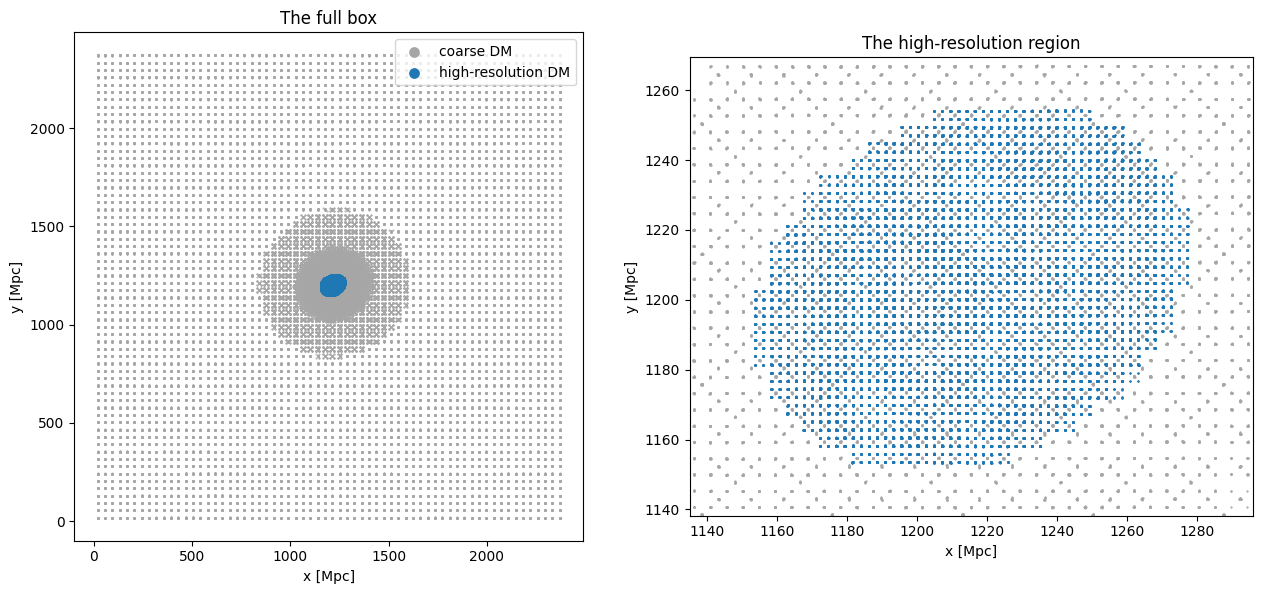

In [4]:
with h5py.File("../data/zoom_ics.hdf5", "r") as handle:
    high = handle["PartType1"]["Coordinates"][:]
    coarse = handle["PartType2"]["Coordinates"][:]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for xyz, colour, label in ((coarse, "0.65", "coarse DM"), (high, "tab:blue", "high-resolution DM")):
    stride = max(1, len(xyz) // 100_000)
    axes[0].scatter(xyz[::stride, 0], xyz[::stride, 1], s=0.2, c=colour, label=label)
    axes[1].scatter(xyz[::stride, 0], xyz[::stride, 1], s=0.4, c=colour, label=label)

padding = 0.15 * np.ptp(high[:, :2], axis=0)
axes[1].set_xlim(high[:, 0].min() - padding[0], high[:, 0].max() + padding[0])
axes[1].set_ylim(high[:, 1].min() - padding[1], high[:, 1].max() + padding[1])
axes[0].set_title("The full box")
axes[1].set_title("The high-resolution region")
for ax in axes:
    ax.set(xlabel="x [Mpc]", ylabel="y [Mpc]")
    ax.set_aspect("equal")
axes[0].legend(markerscale=15)
fig.tight_layout()
plt.show()

The left panel should show the coarse particles filling the whole box. The right panel should reveal the much denser ellipsoidal Lagrangian region. Have a look at the MUSIC log in `runs/music/music.log` if your particle counts differ substantially from the estimate above.

We now have everything needed to explore SWIFT's zoom cell geometry.